Trabalho Final de IAA003 da Aline Vieira Malanovicz

## Os dados

In [318]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# O caminho do arquivo deve ser apenas o nome do arquivo dentro do dataset,
# e não a URL completa do site do Kaggle.
file_path = "netflix_titles.csv"

# Carrega a versão mais recente usando o nome do arquivo correto
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "shivamb/netflix-shows",
  file_path
)

print("First 5 records:")
print(df.head())

Using Colab cache for faster access to the 'netflix-shows' dataset.
First 5 records:
  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1

### Adaptação do Lab: Preparando os dados do Netflix como População
Duração dos Filmes
Ano de lançamento dos Filmes
Ano de lançamento das Séries
Proporção entre Filmes e Séries
Proporção entre Filmes e Séries nos séculos 20 e 21

In [319]:
#print(df['type'].value_counts())

# Contando a quantidade de produções por tipo (Movie vs. TV Show)
df['type'].value_counts()

,count
type,
Movie,6131
TV Show,2676


In [320]:
# Calculando a proporção de cada tipo de produção no catálogo
df['type'].value_counts(normalize=True)

,proportion
type,
Movie,0.696151
TV Show,0.303849


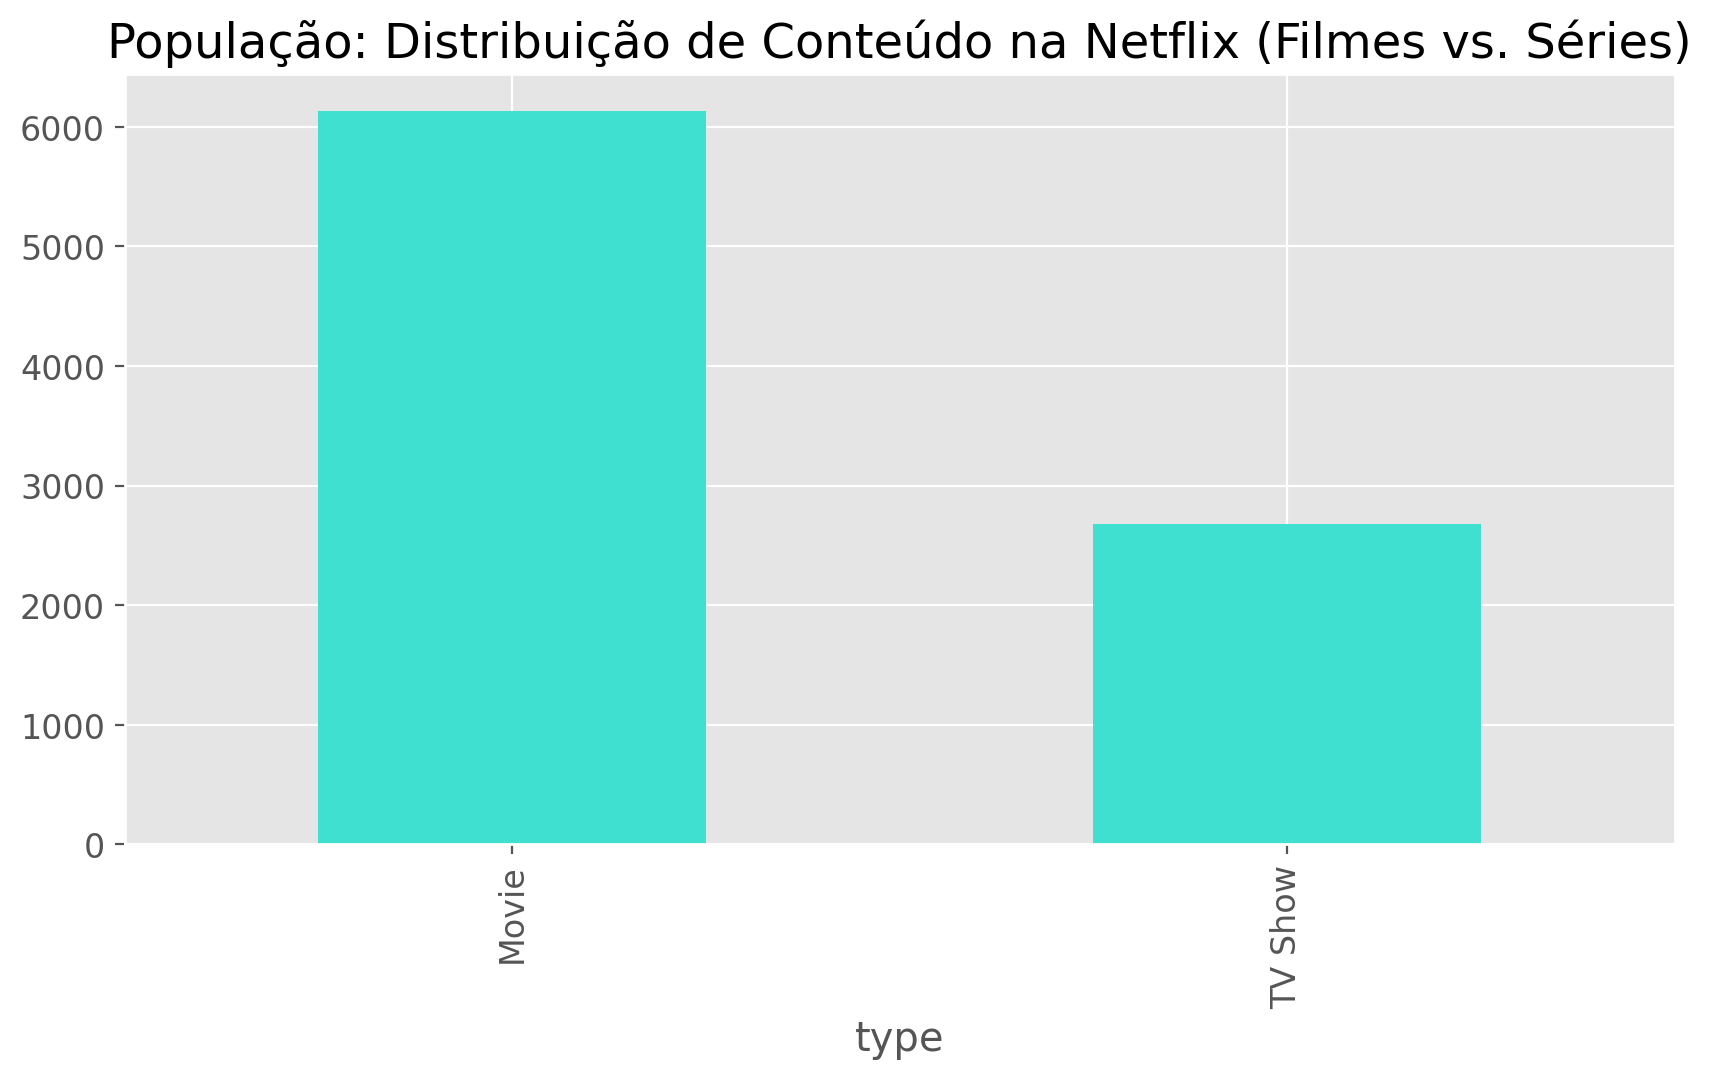

In [321]:
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# Importando a biblioteca de visualização de dados e aplicando o estilo visual
import matplotlib.pyplot as plt
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (10,5)
plt.rcParams['font.size'] = 12
# Gerando um gráfico de barras para os tipos de conteúdo da Netflix
df['type'].value_counts().plot(kind = 'bar', color = 'turquoise',
                               title = 'População: Distribuição de Conteúdo na Netflix (Filmes vs. Séries)')
plt.show();

Tamanho da população (Filmes e séries da Netflix): 8807


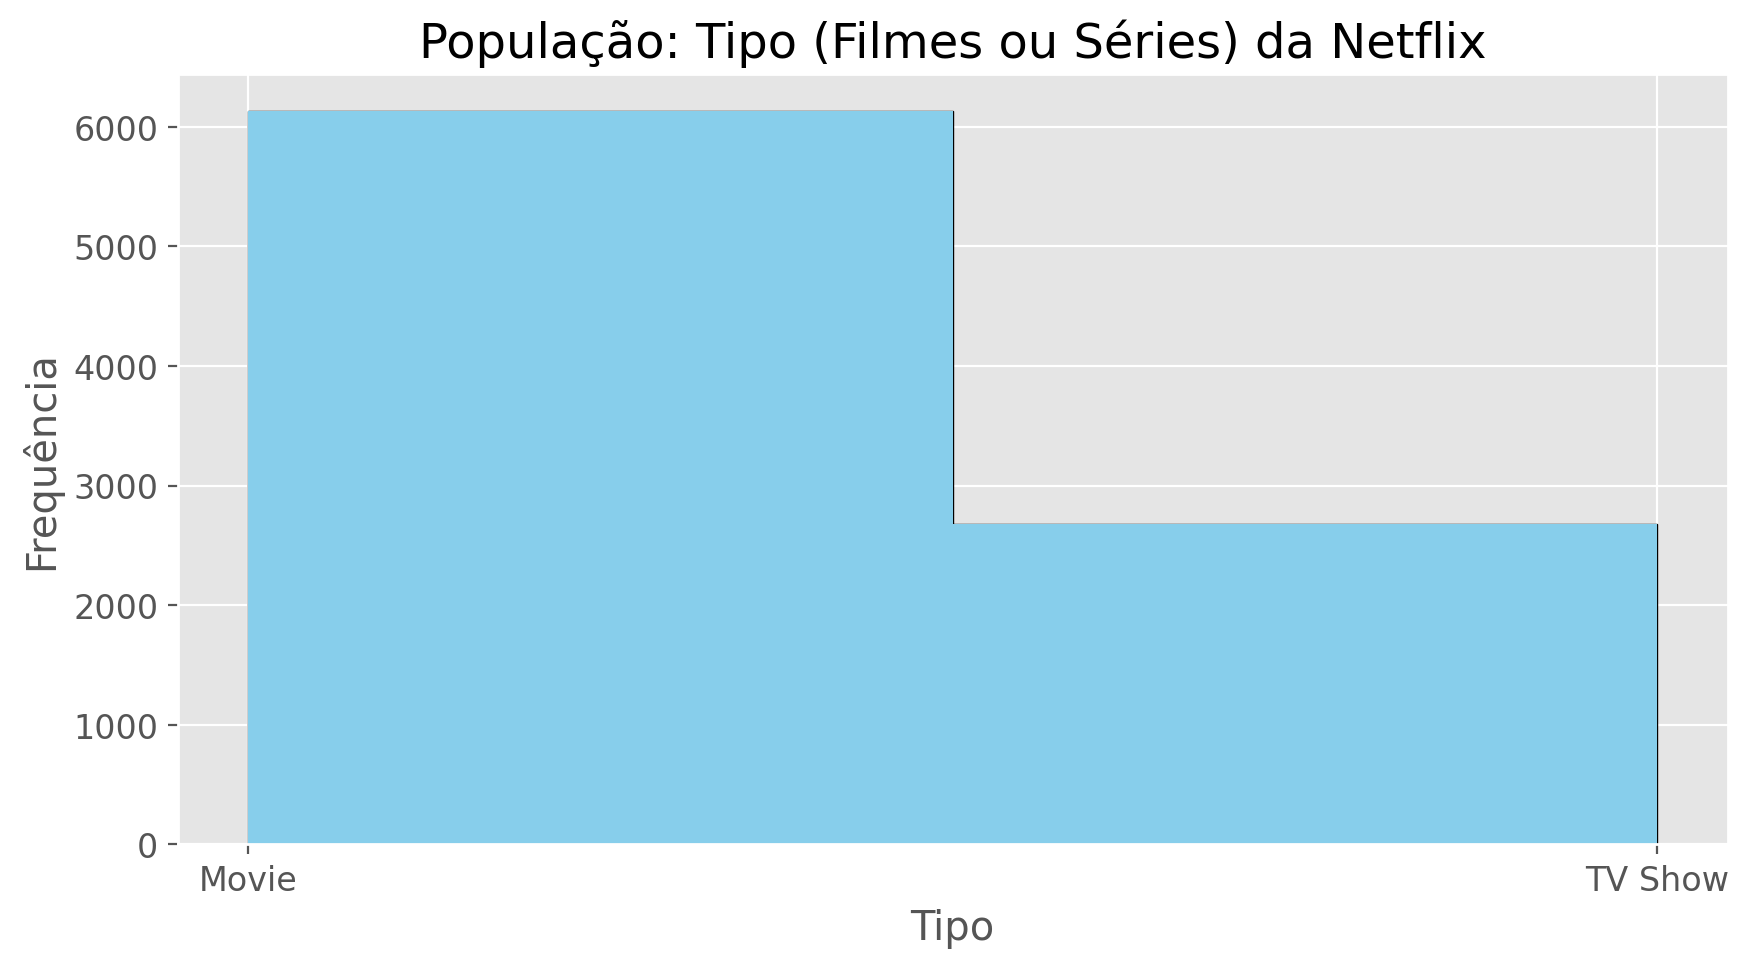

In [322]:
import pandas as pd
import matplotlib.pyplot as plt
movies_series = df.copy()
#movies_series['duration_mins'] = movies_df['type']
movies_series_population = movies_series['type'].dropna()
print(f"Tamanho da população (Filmes e séries da Netflix): {len(movies_series_population)}")

plt.hist(movies_series_population, edgecolor='black', bins=2, color='indianred')
plt.hist(movies_series_population, bins = 2, color='skyblue')
plt.title("População: Tipo (Filmes ou Séries) da Netflix")
plt.xlabel("Tipo")
plt.ylabel("Frequência")
plt.show()


Tamanho da população (Filmes da Netflix): 6128
Média real da população de Filmes: 99.58 minutos


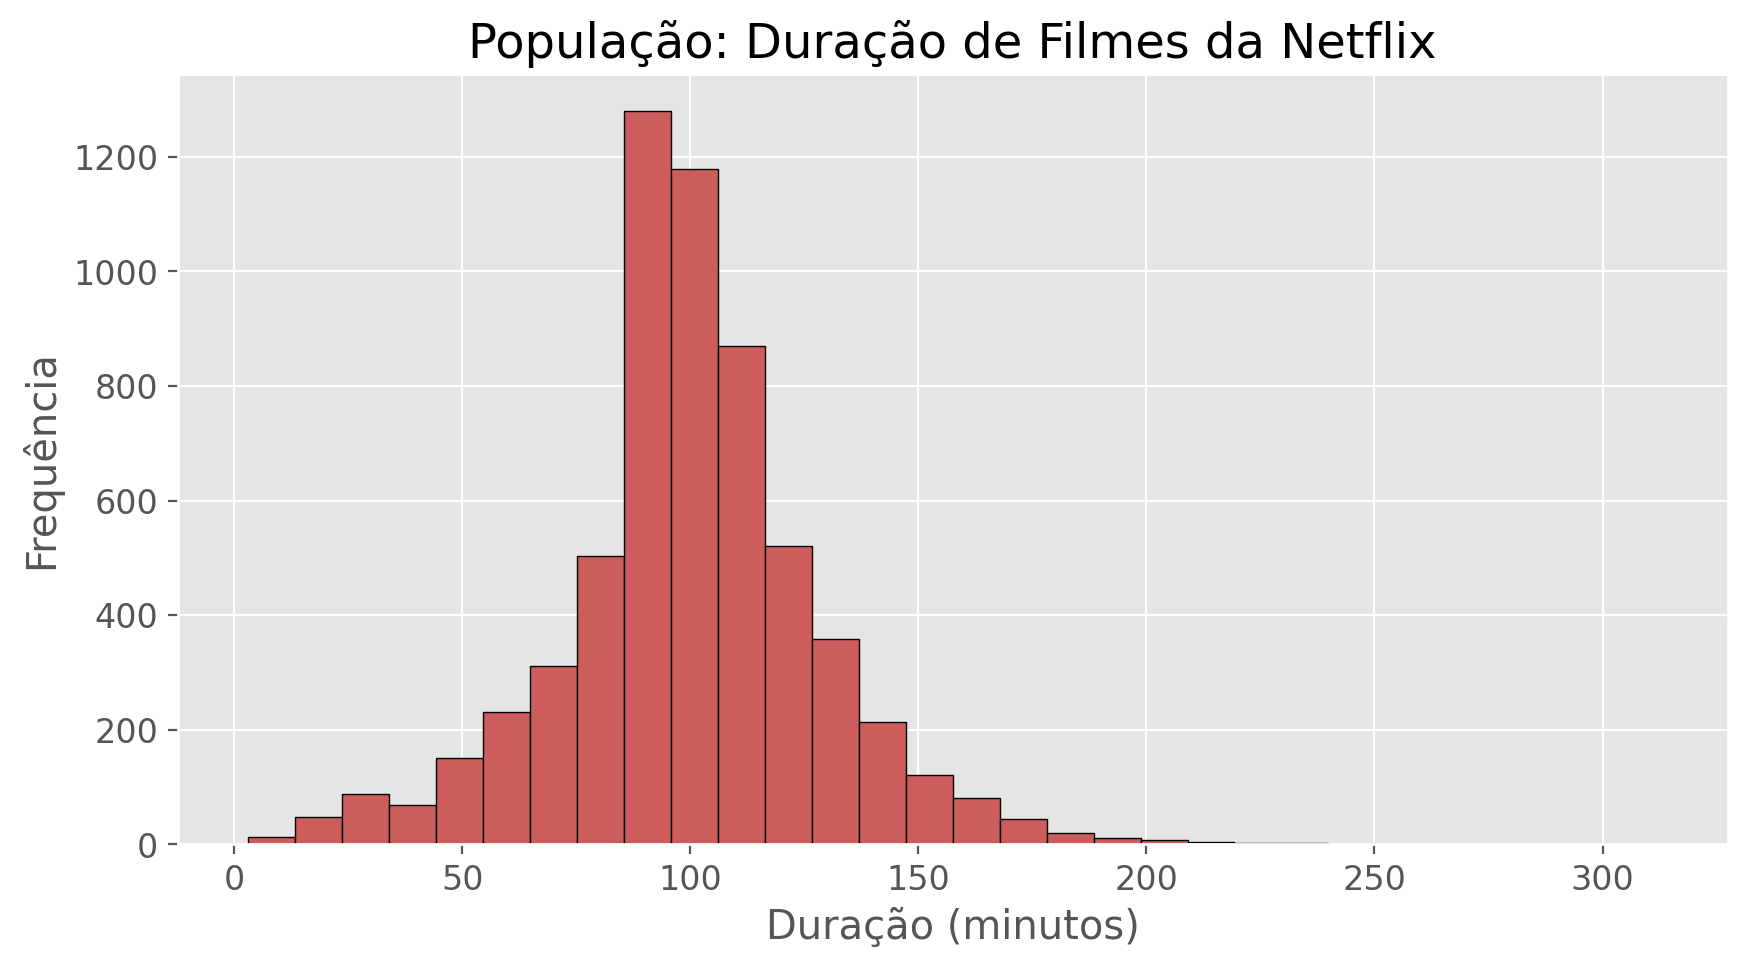

In [323]:
import pandas as pd
import matplotlib.pyplot as plt

# Filtrar apenas os filmes ('Movie') para termos a duração em minutos de forma consistente
movies_df = df[df['type'] == 'Movie'].copy()

# Extrair o número de minutos da coluna duration (ex: "90 min" -> 90)
movies_df['duration_mins'] = movies_df['duration'].str.replace(' min', '').astype(float)

# Remover possíveis valores nulos para manter nossa população limpa
netflix_population = movies_df['duration_mins'].dropna()

print(f"Tamanho da população (Filmes da Netflix): {len(netflix_population)}")
print(f"Média real da população de Filmes: {netflix_population.mean():.2f} minutos")

# Visualizando a nossa nova população de Filmes
plt.hist(netflix_population, edgecolor='black', bins=30, color='indianred')
plt.title("População: Duração de Filmes da Netflix")
plt.xlabel("Duração (minutos)")
plt.ylabel("Frequência")
plt.show()

In [324]:
# Adaptando as variáveis do Lab para usar o Netflix
# Redirecionamos 'area' para a duração dos filmes do Netflix (nossa nova população numérica)
area = netflix_population

# Redirecionamos 'price' para o ano de lançamento dos filmes
price = movies_df['release_year'].dropna()

# Filtrar apenas os filmes ('Movie') para termos a duração em minutos de forma consistente
tipo_df = df.copy()
# Remover possíveis valores nulos para manter nossa população limpa
tipo = tipo_df['type'].dropna()

print(f"Nova população 'area'  configurada! (Duração dos Filmes do Netflix)")
print(f"Nova população 'price' configurada! (Ano de Lançamento dos Filmes do Netflix)")
print(f"Nova população 'tipo'  configurada! (Tipo (Filme ou Série) do Netflix)")

Nova população 'area'  configurada! (Duração dos Filmes do Netflix)
Nova população 'price' configurada! (Ano de Lançamento dos Filmes do Netflix)
Nova população 'tipo'  configurada! (Tipo (Filme ou Série) do Netflix)


In [325]:
print(tipo.describe())

count      8807
unique        2
top       Movie
freq       6131
Name: type, dtype: object


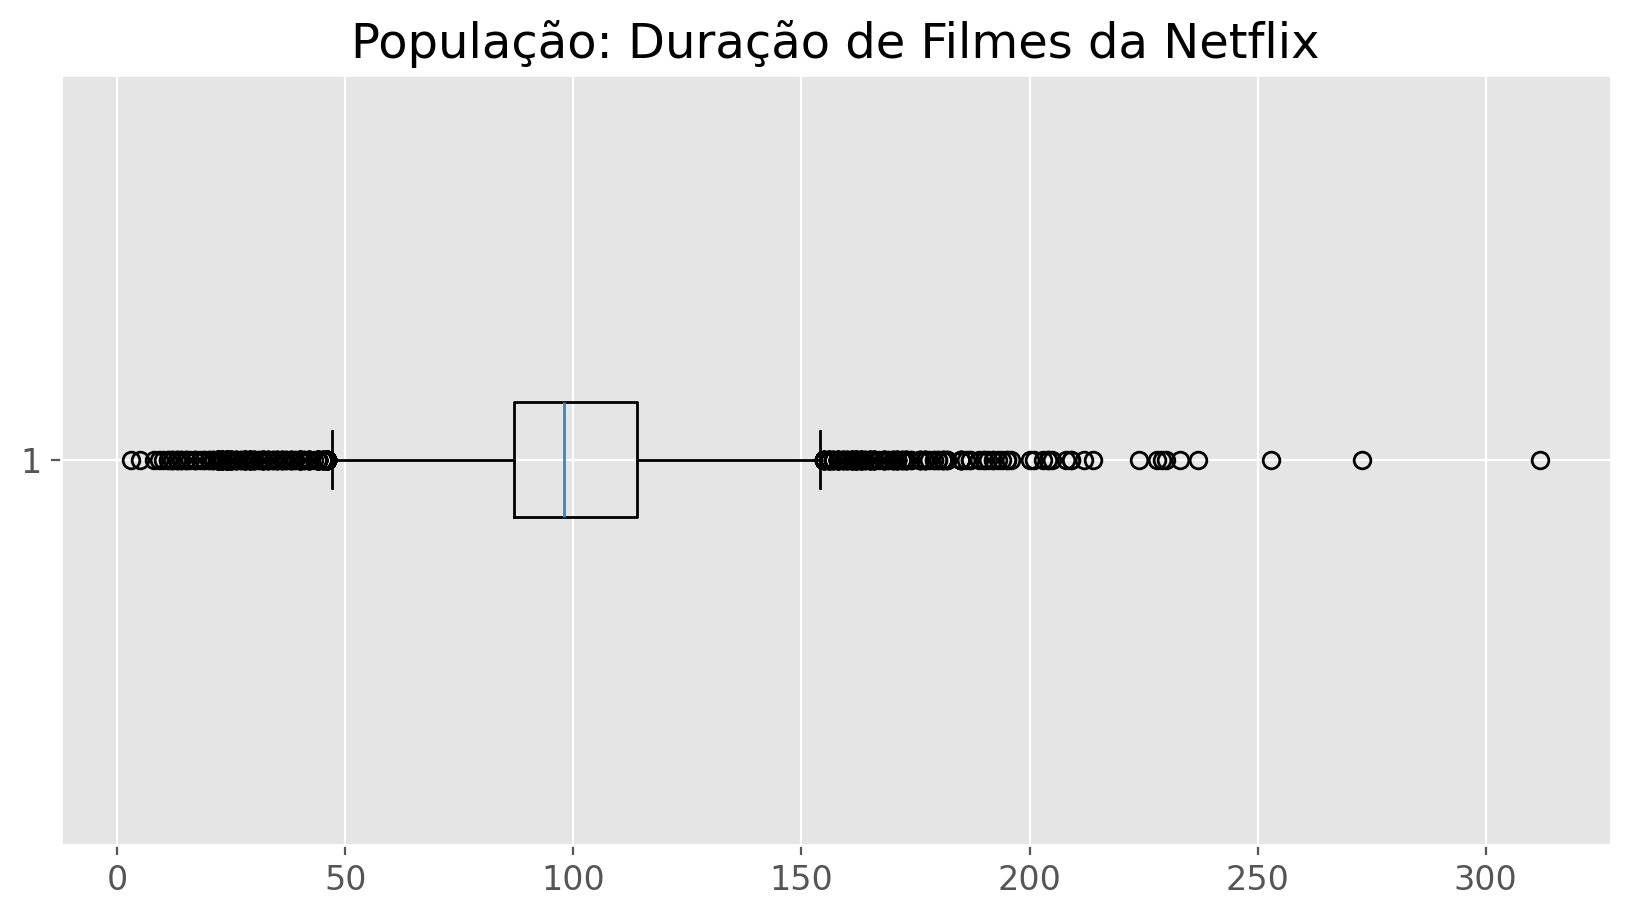

In [326]:
import pandas as pd
import matplotlib.pyplot as plt

# Filtrar apenas os filmes ('Movie') para termos a duração em minutos de forma consistente
movies_df = df[df['type'] == 'Movie'].copy()
series_df = df[df['type'] == 'TV Show'].copy()

# Extrair o número de minutos da coluna duration (ex: "90 min" -> 90)
movies_df['duration_mins'] = movies_df['duration'].str.replace(' min', '').astype(float)
series_df['release_year'] = series_df['release_year'].astype(int)

# Remover possíveis valores nulos para manter nossa população limpa
netflix_population = movies_df['duration_mins'].dropna()
series_population  = series_df['release_year'].dropna()

#print(f"Tamanho da população (Filmes da Netflix): {len(netflix_population)}")
#print(f"Média real da população: {netflix_population.mean():.2f} minutos")

# Visualizando a nossa nova população
#plt.hist(netflix_population, edgecolor='black', bins=30, color='indianred')
#plt.boxplot('duration_mins')
plt.boxplot(netflix_population, orientation = 'horizontal', patch_artist = False)
plt.title("População: Duração de Filmes da Netflix")
#plt.xlabel("Duração (minutos)")
#plt.ylabel("Frequência")
plt.show()

In [327]:
area.describe()

,duration_mins
count,6128.000000
mean,99.577187
std,28.290593
min,3.000000
25%,87.000000
50%,98.000000
75%,114.000000
max,312.000000


In [328]:
#price = movies_df['release_year'].dropna()
price.describe()
#ano de lançamento


,release_year
count,6131.000000
mean,2013.121514
std,9.678169
min,1942.000000
25%,2012.000000
50%,2016.000000
75%,2018.000000
max,2021.000000


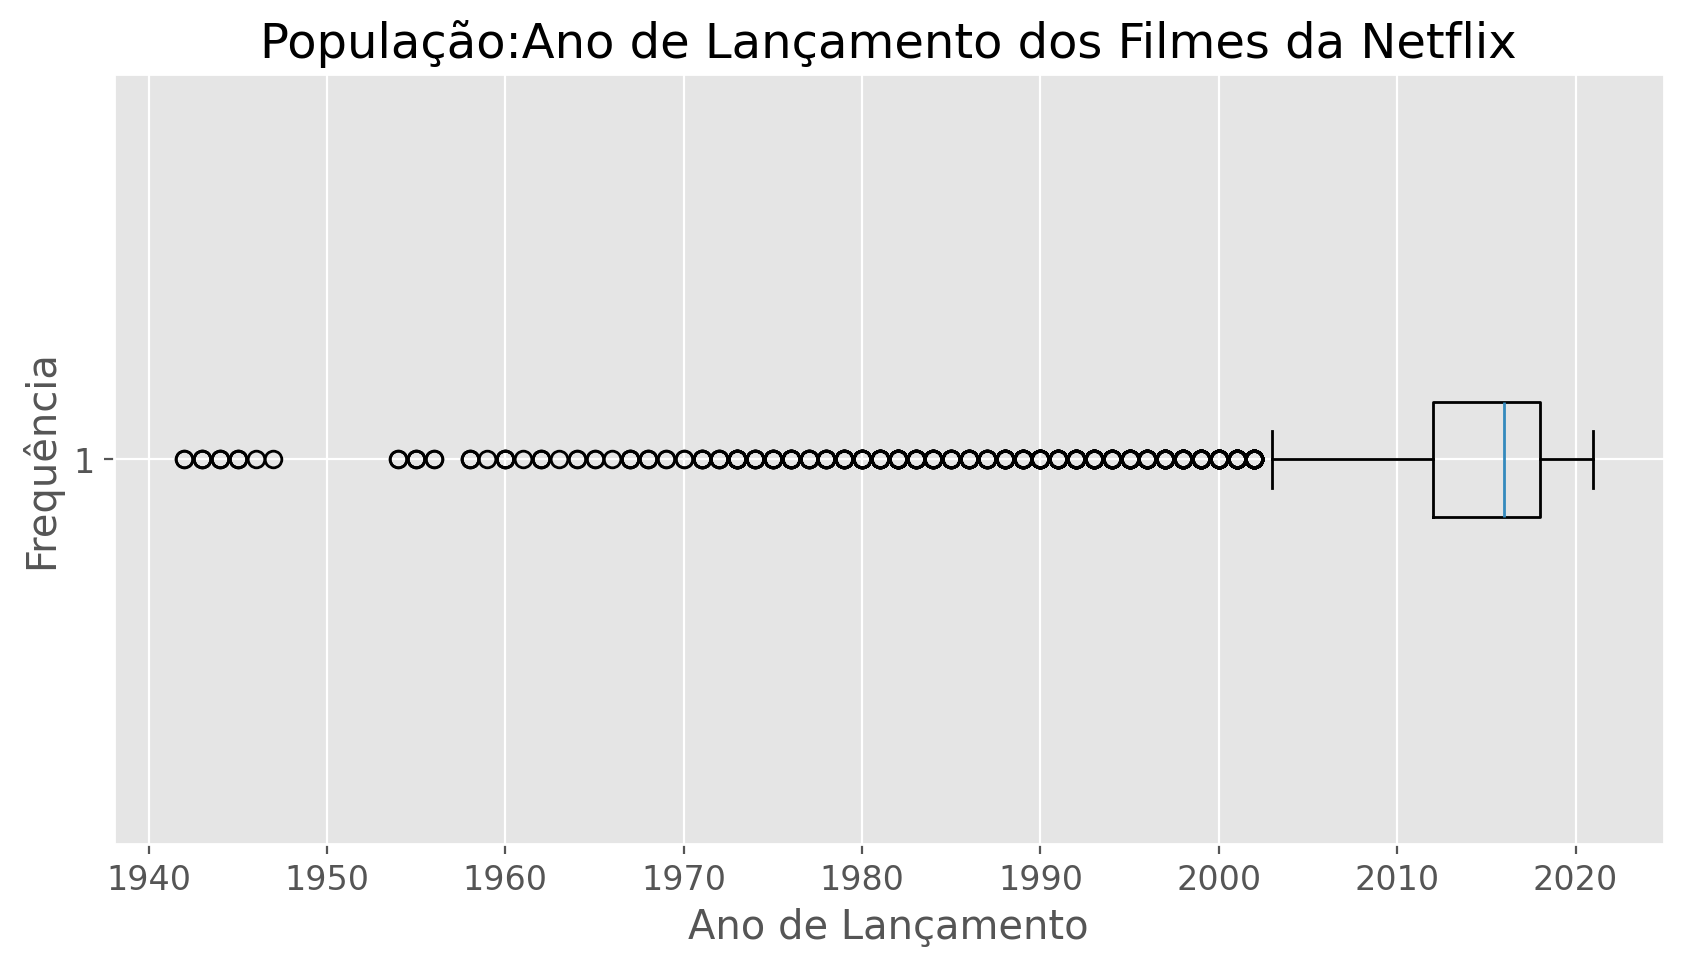

In [329]:
#ano de lançamento
plt.boxplot(price, orientation = 'horizontal', patch_artist = False)
plt.title("População:Ano de Lançamento dos Filmes da Netflix")
plt.xlabel("Ano de Lançamento")
plt.ylabel("Frequência")
plt.show()

In [330]:
import pandas as pd
import matplotlib.pyplot as plt

# Filtrar apenas as series ('TV Show') para termos o ano de lançamento de forma consistente
series_df = df[df['type'] == 'TV Show'].copy()

# Extrair o número de minutos da coluna duration (ex: "90 min" -> 90)
series_df['release_year'] = series_df['release_year'].astype(int)

# Remover possíveis valores nulos para manter nossa população limpa
series_population  = series_df['release_year'].dropna()

#print(f"Tamanho da população (Filmes da Netflix): {len(netflix_population)}")
#print(f"Média real da população: {netflix_population.mean():.2f} minutos")

series_population.describe()

,release_year
count,2676.000000
mean,2016.605755
std,5.740138
min,1925.000000
25%,2016.000000
50%,2018.000000
75%,2020.000000
max,2021.000000


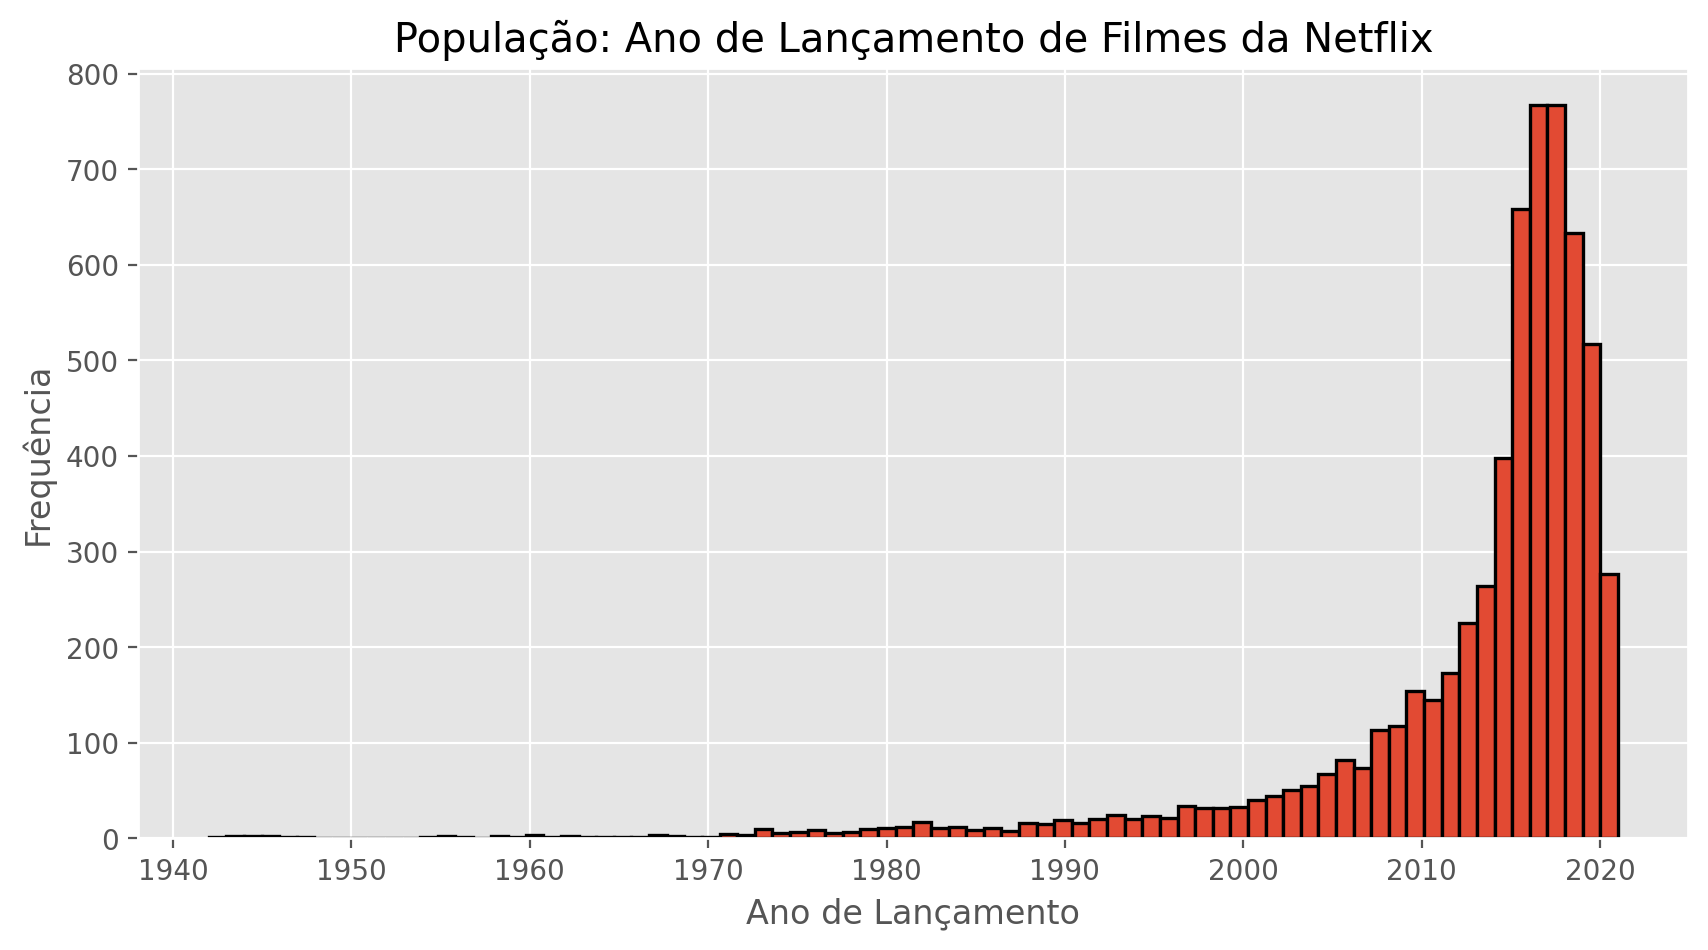

In [331]:
#price = movies_df['release_year'].dropna()
#price.describe()
#ano de lançamento

import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (10,5)

plt.hist(price, edgecolor = 'black', bins = 80, linewidth = 1.2)
plt.title("População: Ano de Lançamento de Filmes da Netflix")
plt.xlabel("Ano de Lançamento")
plt.ylabel("Frequência")
plt.show();

## A distribuição amostral desconhecida

In [332]:
#sampl1 = area.sample(50)
#De acordo com o MonkeySurvey,
#o tamanho da amostra tem que ser 369
#para uma população de 8807 registros,
#com um grau de confiança de 95%
#e uma margem de erro de 5%
sampl1 = area.sample(369)

count    369.000000
mean      96.102981
std       29.882473
min       13.000000
25%       83.000000
50%       97.000000
75%      111.000000
max      195.000000
Name: duration_mins, dtype: float64


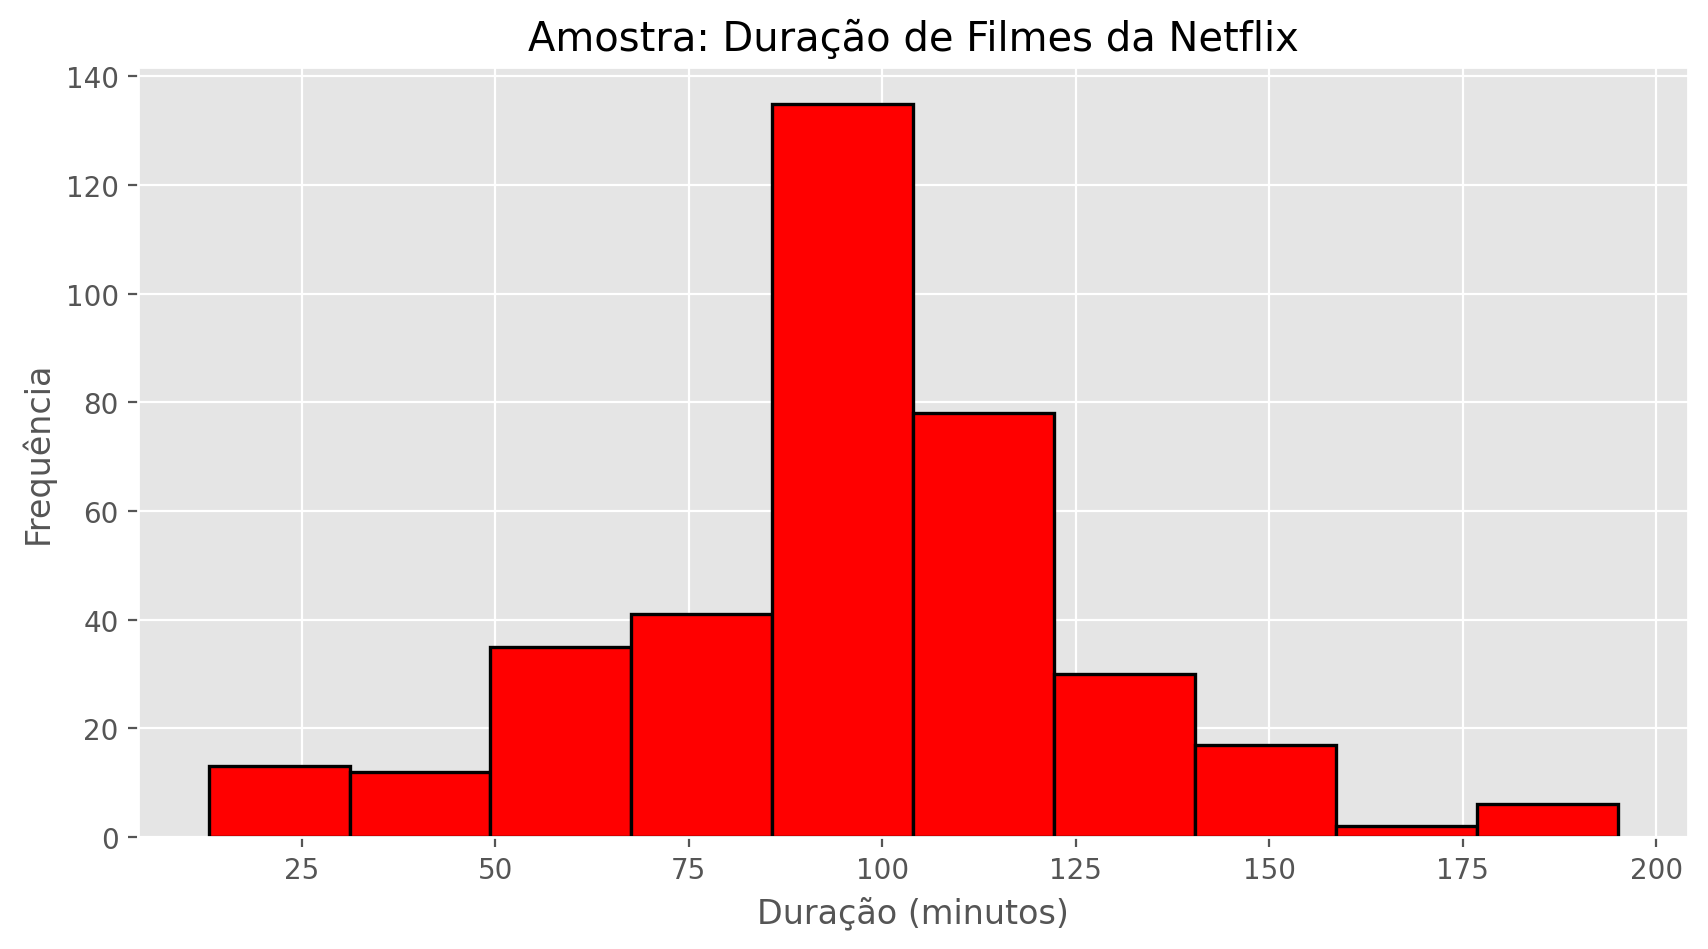

In [333]:
print(sampl1.describe())
plt.hist(sampl1, color = 'red', edgecolor = 'black', linewidth = 1.2)
plt.title("Amostra: Duração de Filmes da Netflix")
plt.xlabel("Duração (minutos)")
plt.ylabel("Frequência")
plt.show()
# R. O objetivo é que ela seja representativa da população

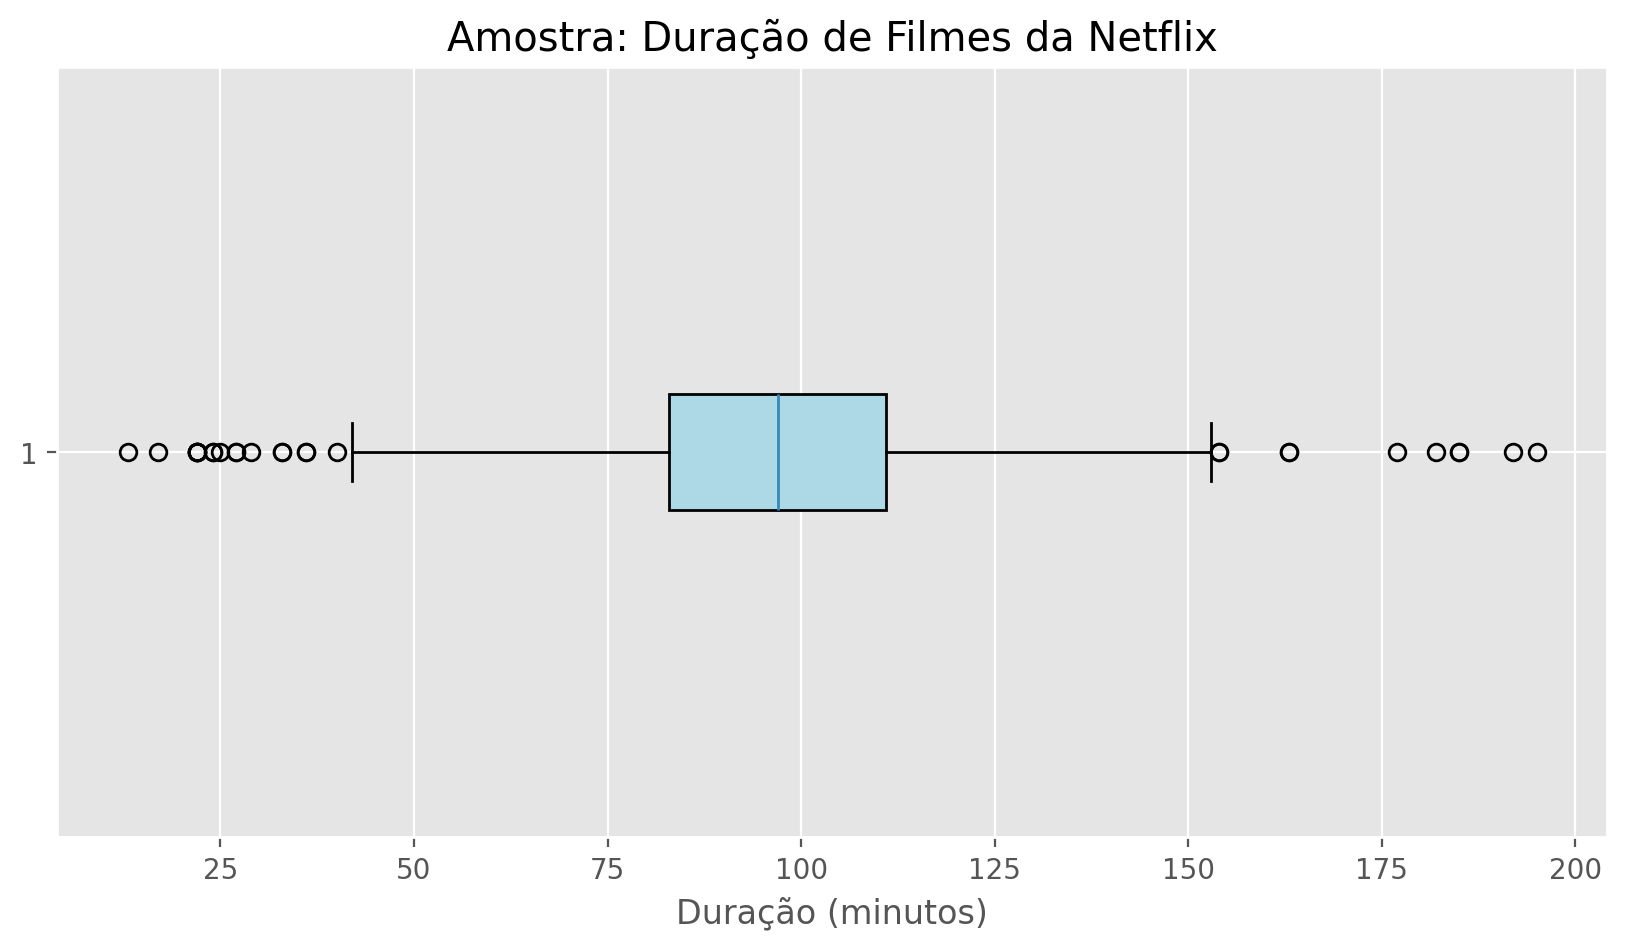

In [334]:
import pandas as pd
import matplotlib.pyplot as plt

# Como 'sampl1' já é uma Série numérica contendo apenas a duração (em minutos)
# de uma amostra de filmes, não precisamos filtrar novamente usando 'type'.
netflix_sampl1 = sampl1.dropna()

# Visualizando a duração de filmes na nossa amostra
plt.boxplot(netflix_sampl1, vert=False, patch_artist=True, boxprops=dict(facecolor="lightblue"))
plt.title("Amostra: Duração de Filmes da Netflix")
plt.xlabel("Duração (minutos)")
plt.show()

In [335]:
sampl1.mean()

np.float64(96.1029810298103)

In [336]:
area.mean()

np.float64(99.57718668407311)

In [337]:
sampl2 = tipo.sample(369)
#amostragem para o tipo
sampl2.value_counts()

,count
type,
Movie,256
TV Show,113


In [338]:
sampl2.value_counts(normalize=True)

,proportion
type,
Movie,0.693767
TV Show,0.306233


Tamanho da amostra (Filmes e séries da Netflix): 369


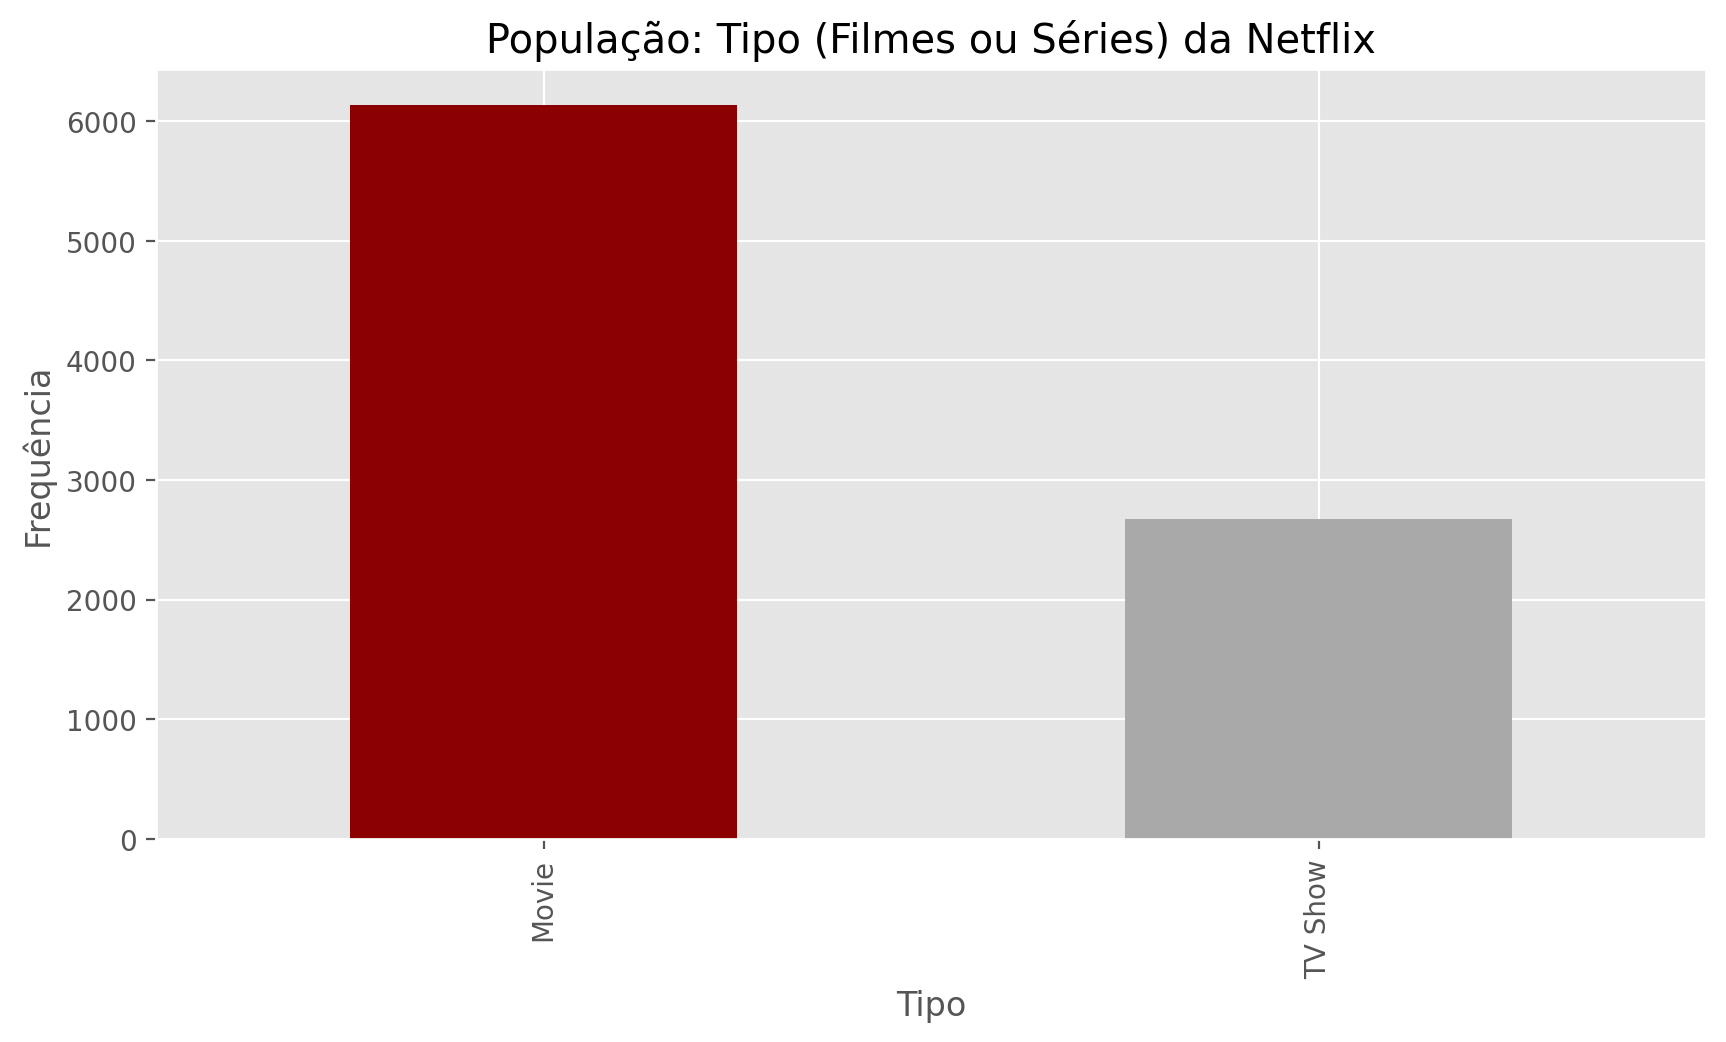

In [339]:
import pandas as pd
import matplotlib.pyplot as plt
#movies_series = tipo.copy()
movies_series = sampl2.copy()
#movies_series['duration_mins'] = movies_df['type']
movies_series_amostra = movies_series.dropna()
print(f"Tamanho da amostra (Filmes e séries da Netflix): {len(movies_series_amostra)}")

#plt.hist(movies_series_amostra, edgecolor='black', bins=2, color='lightblue')
df['type'].value_counts().plot(kind='bar', color = ['darkred', 'darkgray'])
#plt.hist(movies_series_amostra, bins = 2, color='skyblue')
plt.title("População: Tipo (Filmes ou Séries) da Netflix")
plt.xlabel("Tipo")
plt.ylabel("Frequência")
plt.show()

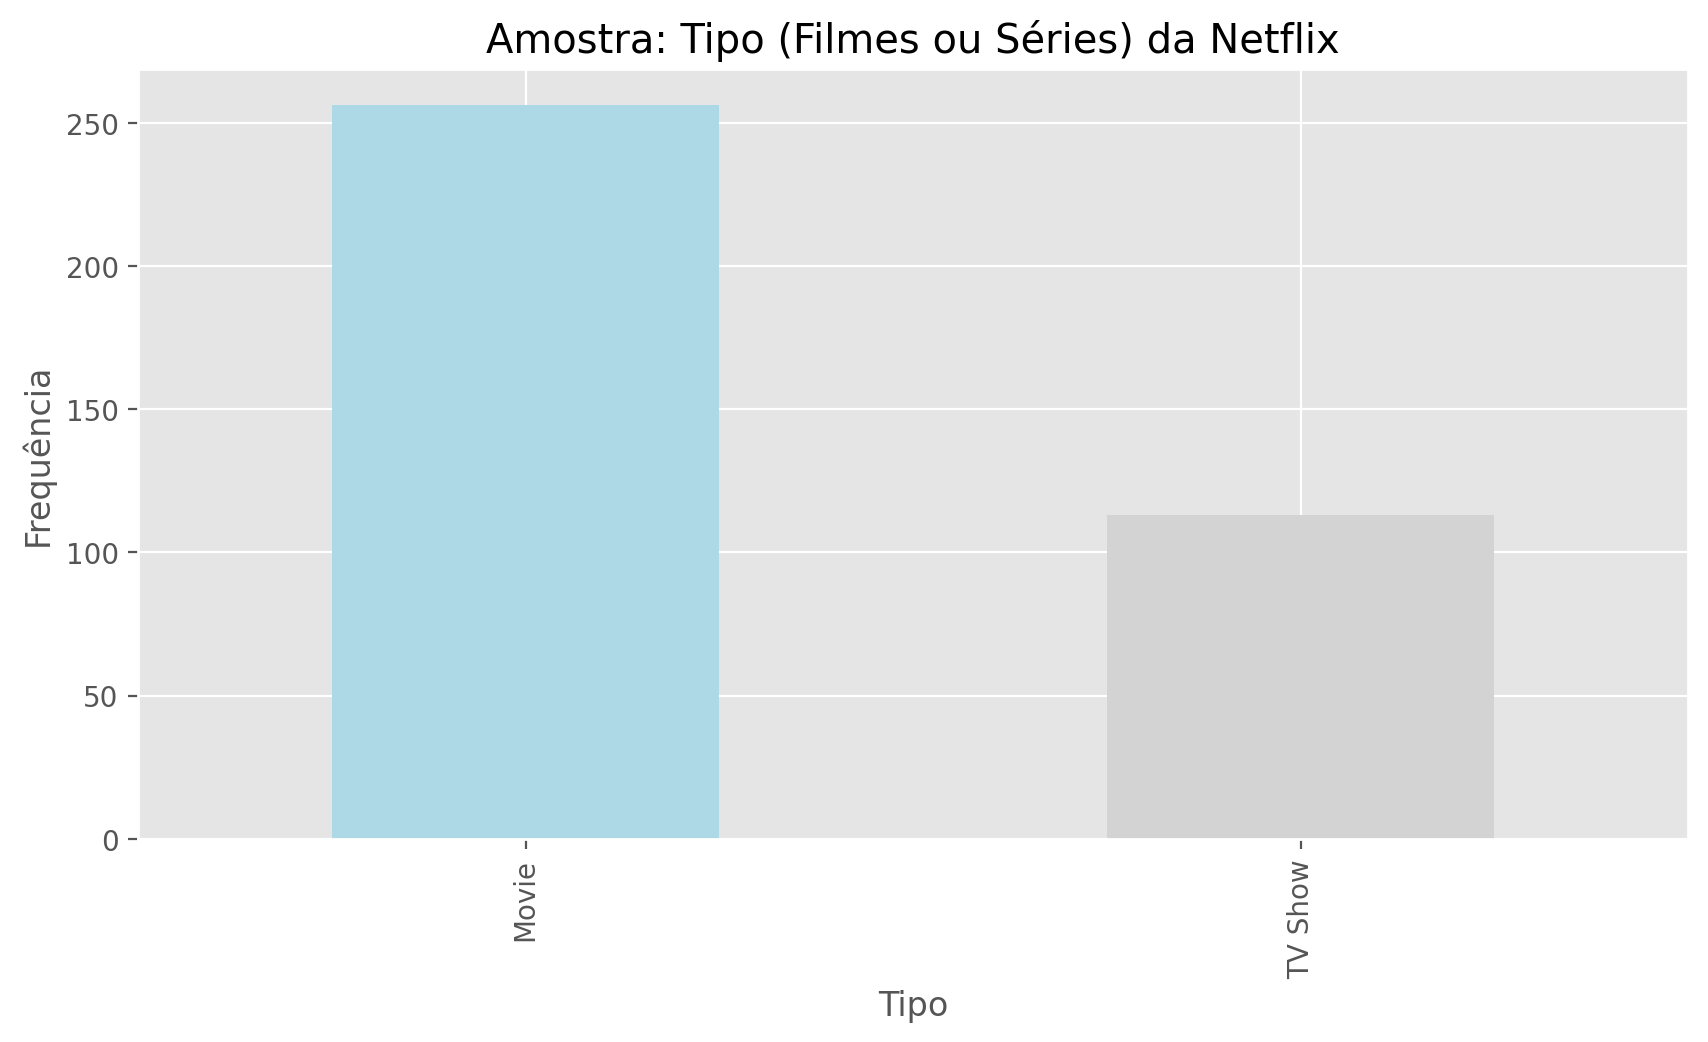

In [340]:
import pandas as pd
import matplotlib.pyplot as plt

movies_series = sampl2.copy()
movies_series_amostra = movies_series.dropna()
#print(f"Tamanho da amostra (Filmes e séries da Netflix): {len(movies_series_amostra)}")

movies_series_amostra.value_counts().plot(kind='bar', color = ['lightblue', 'lightgray'])
plt.title("Amostra: Tipo (Filmes ou Séries) da Netflix")
plt.xlabel("Tipo")
plt.ylabel("Frequência")
plt.show()

In [341]:
sampl3 = price.sample(369)
#amostragem para o ano de lançamento
sampl3.value_counts()
sampl3.describe()

,release_year
count,369.000000
mean,2011.897019
std,10.792772
min,1955.000000
25%,2010.000000
50%,2016.000000
75%,2018.000000
max,2021.000000


Tamanho da amostra (Ano de Lançamento dos Filmes da Netflix): 369


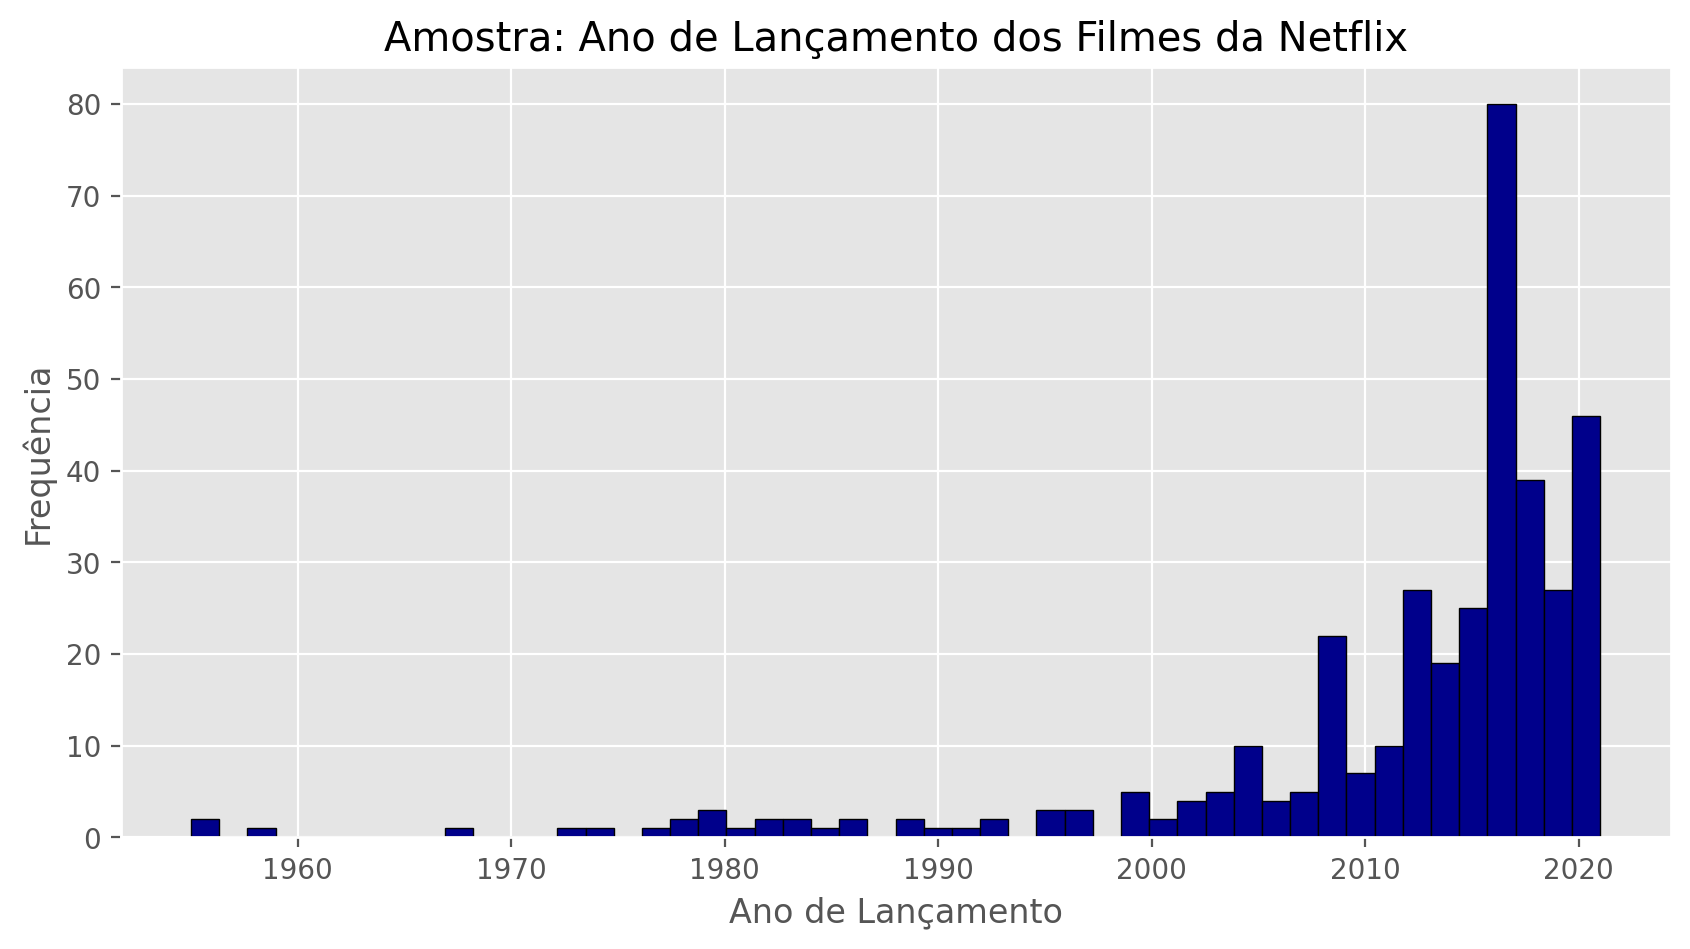

In [342]:
import pandas as pd
import matplotlib.pyplot as plt
movies_ano = sampl3.copy()
movies_ano_amostra = movies_ano.dropna()
print(f"Tamanho da amostra (Ano de Lançamento dos Filmes da Netflix): {len(movies_ano_amostra)}")

plt.hist(movies_ano_amostra, edgecolor='black', bins=50, color='darkblue')
plt.title("Amostra: Ano de Lançamento dos Filmes da Netflix")
plt.xlabel("Ano de Lançamento")
plt.ylabel("Frequência")
plt.show()

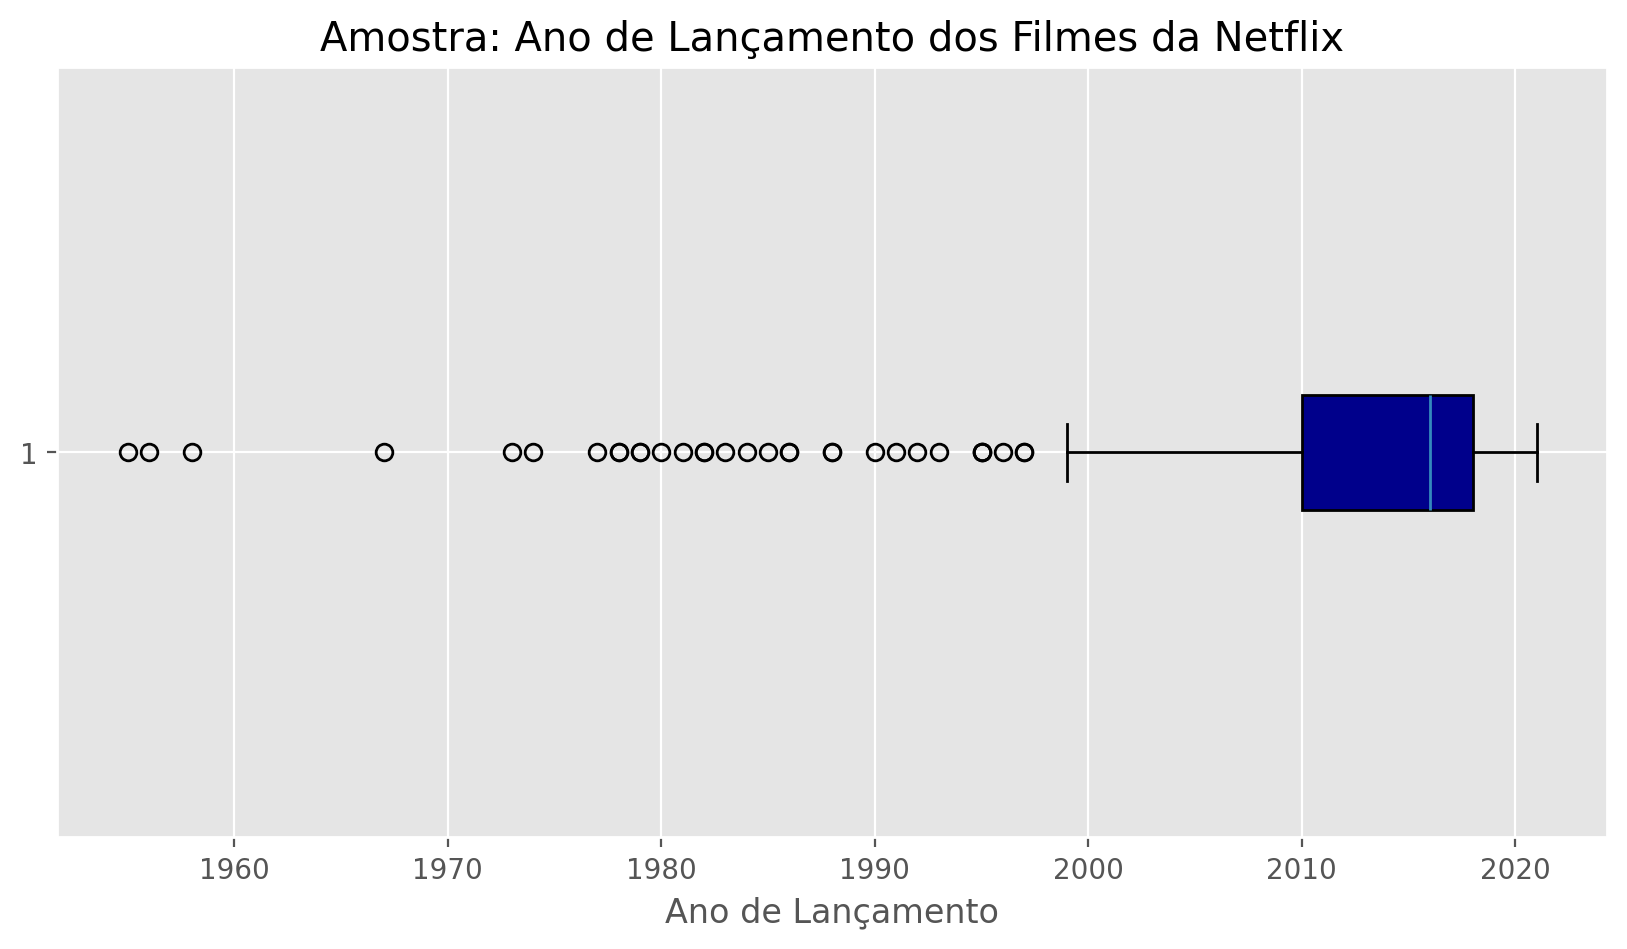

In [343]:
import pandas as pd
import matplotlib.pyplot as plt

# Como 'sampl2' já é uma Série numérica (ordinal) contendo apenas o ano de lançamento
# de uma amostra de filmes, não precisamos filtrar novamente usando 'type'.
netflix_sampl3 = sampl3.dropna()

# Visualizando o ano de duração na nossa amostra
plt.boxplot(netflix_sampl3, vert=False, patch_artist=True, boxprops=dict(facecolor="darkblue"))
plt.title("Amostra: Ano de Lançamento dos Filmes da Netflix")
plt.xlabel("Ano de Lançamento")
plt.show()

In [344]:
sampl4 = series_population.sample(369)
#amostragem para o ano de lançamento das series
sampl4.value_counts()
sampl4.describe()

,release_year
count,369.000000
mean,2016.542005
std,7.537154
min,1925.000000
25%,2016.000000
50%,2018.000000
75%,2020.000000
max,2021.000000


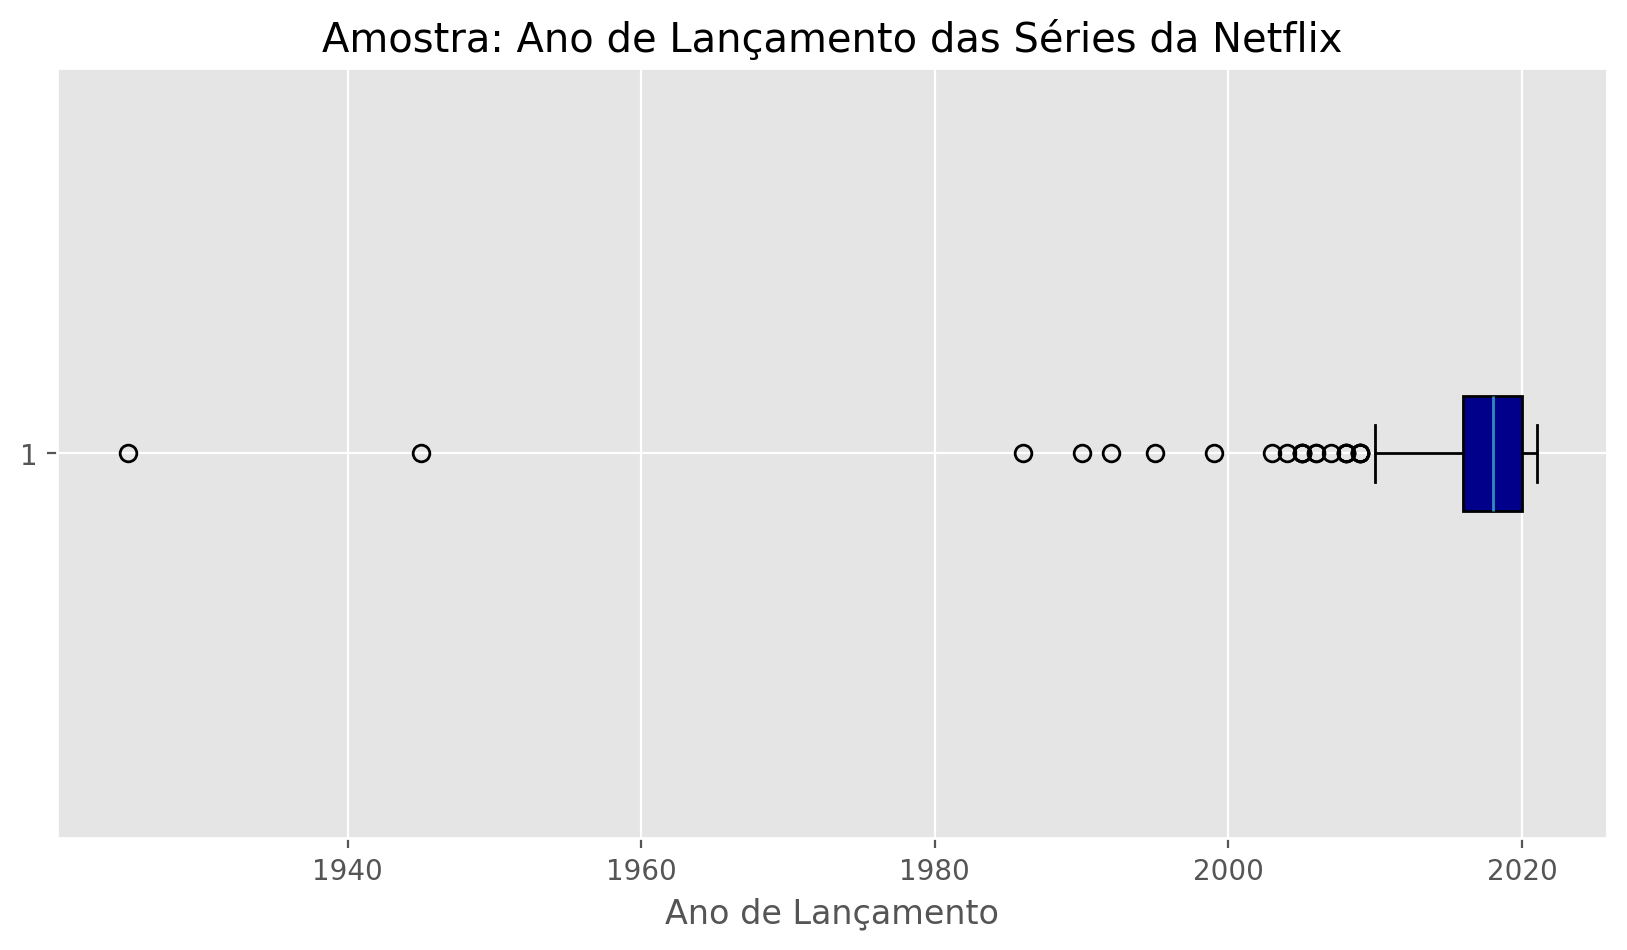

In [345]:
import pandas as pd
import matplotlib.pyplot as plt

# Como 'sampl2' já é uma Série numérica (ordinal) contendo apenas o ano de lançamento
# de uma amostra de filmes, não precisamos filtrar novamente usando 'type'.
netflix_sampl4 = sampl4.dropna()

# Visualizando o ano de duração na nossa amostra de séries
plt.boxplot(netflix_sampl4, vert=False, patch_artist=True, boxprops=dict(facecolor="darkblue"))
plt.title("Amostra: Ano de Lançamento das Séries da Netflix")
plt.xlabel("Ano de Lançamento")
plt.show()

In [346]:
import numpy as np

print(f"Tamanho da amostra: ", sampl1.count())
sampl1_duracao_mean = sampl1.mean()
print(f"Média da amostra: {sampl1_duracao_mean} minutos")
se1_duracao = np.std(sampl1)/np.sqrt(369)
print(f"Desvio padrão da amostra: {se1_duracao} minutos")
print(f"Variância da amostra: {(se1_duracao * se1_duracao)} minutos^2")
lower1_duracao = sampl1_duracao_mean - (1.96 * se1_duracao)
upper1_duracao = sampl1_duracao_mean + (1.96 * se1_duracao)
print(f"Intervalo de estimação para média da \n Duração dos Filmes da Netflix (min): \n",
      lower1_duracao, upper1_duracao)
print(f"Média real da população:", area.mean(), "\n Ufa!")

Tamanho da amostra:  369
Média da amostra: 96.1029810298103 minutos
Desvio padrão da amostra: 1.5535100918621325 minutos
Variância da amostra: 2.4133936055174914 minutos^2
Intervalo de estimação para média da 
 Duração dos Filmes da Netflix (min): 
 93.05810124976051 99.14786080986008
Média real da população: 99.57718668407311 
 Ufa!


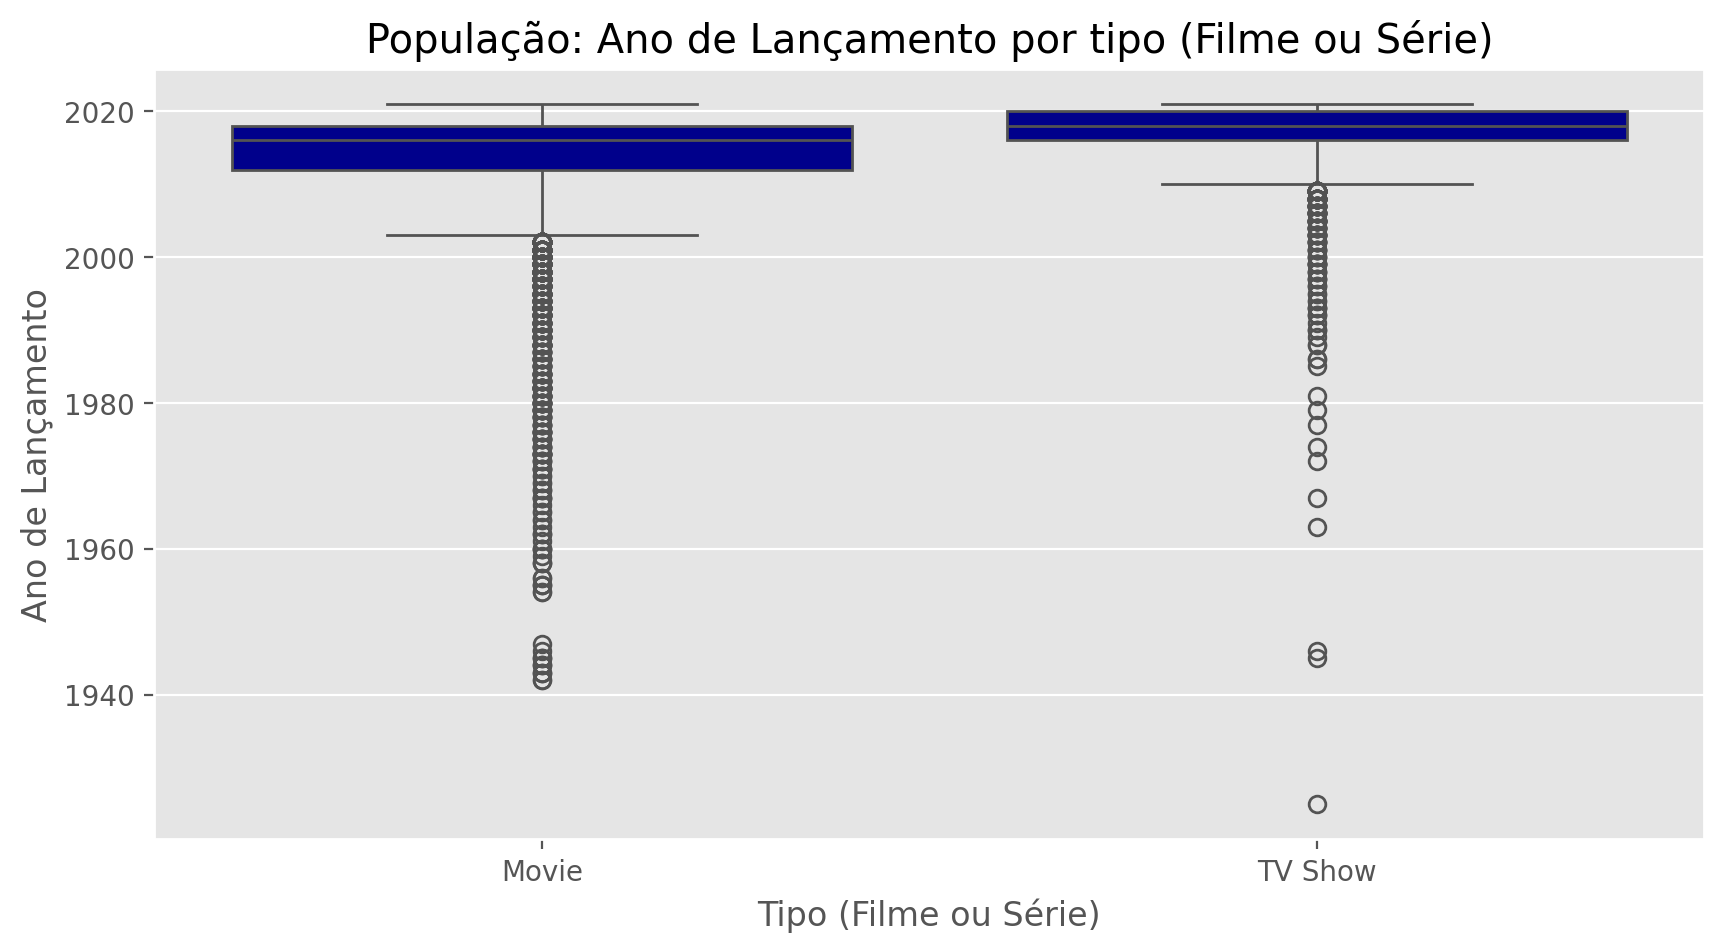

In [347]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=df, x='type', y='release_year', vert=True,  boxprops=dict(facecolor="darkblue"))
plt.title('População: Ano de Lançamento por tipo (Filme ou Série)')
plt.xlabel('Tipo (Filme ou Série)')
plt.ylabel('Ano de Lançamento')
plt.show()
#Parece que as séries são mais recentes (têm ano de lançamento maior).

Hipóteses para testar se os anos médios de
lançamento dos filmes e séries são diferentes:

H0:μSéries=μFilmes

H1:μSéries≠μFilmes

In [348]:
import statsmodels.stats.weightstats as st
df_anoANDfilmes = df[df['type'] ==   'Movie']['release_year']
df_anoANDseries = df[df['type'] == 'TV Show']['release_year']
dsw1 = st.DescrStatsW(df_anoANDfilmes)
dsw2 = st.DescrStatsW(df_anoANDseries)
cm = st.CompareMeans(dsw1, dsw2)
# Calcule o número de observações, a média e o desvio padrão para cada grupo.
n_filmes = dsw1.nobs
n_series = dsw2.nobs
mean_filmes = dsw1.mean
mean_series = dsw2.mean
sd_filmes = dsw1.std
sd_series = dsw2.std
print(f'n_filmes = {n_filmes}')
print(f'mean_filmes = {mean_filmes}')
print(f'sd_filmes = {sd_filmes}')
print()
print(f'n_series = {n_series}')
print(f'mean_series = {mean_series}')
print(f'sd_series = {sd_series}')
print()
# realizar teste de hipótese
ht = cm.ztest_ind(alternative = 'two-sided', usevar = 'unequal', value = 0)
# calcule e imprima o erro padrão, o escore Z e o valor-p para o teste de hipótese.
se = cm.std_meandiff_separatevar
testZ = ht[0]
p_value = ht[1]
print(f'Standard error = {se}')
print(f'Test statistic: Z = {testZ}')
print(f'p-value = {p_value}')
# rejeitar ou aceitar a hipótese nula
if(p_value) < 0.05:
    print('\n rejeitar a hipótese nula')
else:
    print('\n aceitar a hipótese nula')

n_filmes = 6131.0
mean_filmes = 2013.1215136193116
sd_filmes = 9.677379998375049

n_series = 2676.0
mean_series = 2016.605754857997
sd_series = 5.739065491106182

Standard error = 0.1661037293357962
Test statistic: Z = -20.976297477593885
p-value = 1.0798063225568395e-97

 rejeitar a hipótese nula


In [349]:
import numpy as np

print(f"Tamanho da amostra: ", sampl3.count())
sampl3_ano_mean = sampl3.mean()
print(f"Média da amostra: {sampl1_duracao_mean} anos")
se3_ano = np.std(sampl3)/np.sqrt(369)
print(f"Desvio padrão da amostra: {se3_ano} anos")
print(f"Variância da amostra: {(se3_ano * se3_ano)} anos^2")
lower3_ano = sampl3_ano_mean - (1.96 * se3_ano)
upper3_ano = sampl3_ano_mean + (1.96 * se3_ano)
print(f"Intervalo de estimação para média do \n Ano de Lançamento dos Filmes da Netflix: \n",
      lower3_ano, upper3_ano)
print(f"Média real da população:", price.mean(), "\n Ufa!")

Tamanho da amostra:  369
Média da amostra: 96.1029810298103 anos
Desvio padrão da amostra: 0.5610874475852368 anos
Variância da amostra: 0.3148191238377158 anos^2
Intervalo de estimação para média do 
 Ano de Lançamento dos Filmes da Netflix: 
 2010.7972875729226 2012.9967503674568
Média real da população: 2013.1215136193116 
 Ufa!


In [350]:
import numpy as np

#df['type'].value_counts(normalize=True) * 100
sampl2_proporcao = sampl2.value_counts(normalize=True) * 100
#print(sampl2_proporcao)

#sampl2_mean = sampl1.proportion()
se2_tipo = np.std(sampl2_proporcao)/np.sqrt(369)
#print(se2)
lower2_tipo = sampl2_proporcao - (1.95 * se2_tipo)
upper2_tipo = sampl2_proporcao + (1.95 * se2_tipo)
print(f"Intervalo de estimação para proporção entre Séries e Filmes da Netflix:", lower2_tipo, upper2_tipo)
print(f"Proporção real da população:", df['type'].value_counts(normalize=True) * 100, "Ufa!")

Intervalo de estimação para proporção entre Séries e Filmes da Netflix: type
Movie      67.409709
TV Show    28.656321
Name: proportion, dtype: float64 type
Movie      71.343679
TV Show    32.590291
Name: proportion, dtype: float64
Proporção real da população: type
Movie      69.615079
TV Show    30.384921
Name: proportion, dtype: float64 Ufa!


In [351]:
import numpy as np
from scipy.stats import norm

conf_lvl = 0.95
z_value = norm.ppf((1-(1-conf_lvl)/2))  # o valor Z para o nível de confiança especificado
prbs = tipo.value_counts(normalize = True)  # as probabilidades para Séries e Filmes
se = np.sqrt(prbs.prod()/len(tipo))  # o erro padrão

# construir um intervalo de confiança de 95% para a proporção de Séries e Filmes
ci1 = prbs['Movie'] - z_value * se
ci2 = prbs['Movie'] + z_value * se

# imprimir os resultados
print(f'Number of successes (Filmes) = {len(tipo)*prbs[1]}')
print(f'Number of failures (Séries)  = {len(tipo)*prbs[0]}')
print(f'Standard error = {se}')
print(f'{int(conf_lvl*100)}% confidence interval = {ci1, ci2}')

Number of successes (Filmes) = 2676.0
Number of failures (Séries)  = 6131.0
Standard error = 0.0049007970506160245
95% confidence interval = (np.float64(0.6865454034302507), np.float64(0.7057561748597458))


=== POPULAÇÃO TOTAL ===

Quantidades por Período e Tipo:


type,Movie,TV Show
periodo,,
Século 20,509,53
Século 21,5622,2623



Proporções por Período e Tipo:


type,Movie,TV Show
periodo,,
Século 20,0.905694,0.094306
Século 21,0.681868,0.318132



=== AMOSTRA DA NOVA POPULAÇÃO (n=369) ===


type,Movie,TV Show
periodo,,
Século 20,21,1
Século 21,222,125



Proporções por Período e Tipo:


type,Movie,TV Show
periodo,,
Século 20,0.954545,0.045455
Século 21,0.639769,0.360231


<Figure size 1000x600 with 0 Axes>

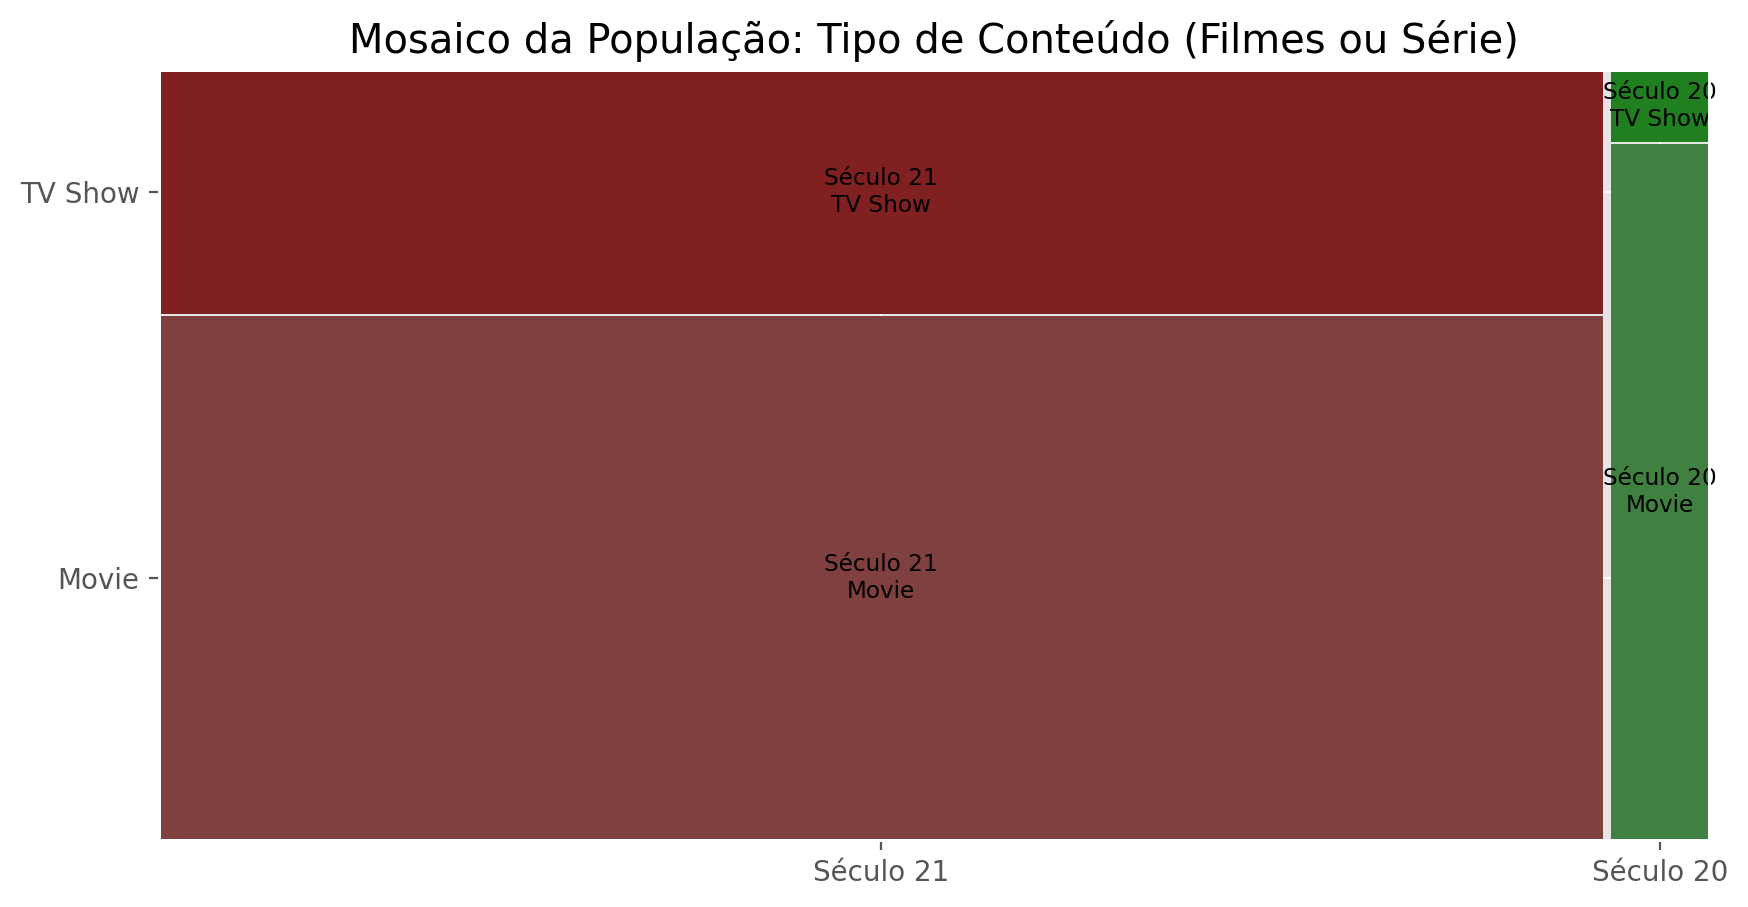

In [352]:
import pandas as pd
import numpy as np
from statsmodels.graphics.mosaicplot import mosaic
import matplotlib.pyplot as plt
import scipy.stats as stats

# Filtrando apenas produções lançadas a partir do ano 2000
pop_df = df.copy()

# 1. Definindo os períodos estruturados em século 20 e século 21
def categorizar_periodo(ano):
    if ano < 2001:
        return 'Século 20'
    else:
        return 'Século 21'

pop_df['periodo'] = pop_df['release_year'].apply(categorizar_periodo)

# Tabela de contingência da população (Quantidades e Proporções)
tabela_pop = pd.crosstab(pop_df['periodo'], pop_df['type'])
tabela_pop_prop = pd.crosstab(pop_df['periodo'], pop_df['type'], normalize='index')

print("=== POPULAÇÃO TOTAL ===")
print("\nQuantidades por Período e Tipo:")
display(tabela_pop)
print("\nProporções por Período e Tipo:")
display(tabela_pop_prop)

# 2. Extraindo uma nova amostra aleatória de tamanho 369
amostra_df = pop_df.sample(n=369, random_state=42)
tabela_amostra = pd.crosstab(amostra_df['periodo'], amostra_df['type'])
tabela_amostra_prop = pd.crosstab(amostra_df['periodo'], amostra_df['type'], normalize='index')

print("\n=== AMOSTRA DA NOVA POPULAÇÃO (n=369) ===")
display(tabela_amostra)

print("\nProporções por Período e Tipo:")
display(tabela_amostra_prop)

# 3. Gráfico de Mosaico para a Nova População
plt.figure(figsize=(10, 6))
mosaic(pop_df, ['periodo', 'type'],
       title='Mosaico da População: Tipo de Conteúdo (Filmes ou Série)')
plt.show()

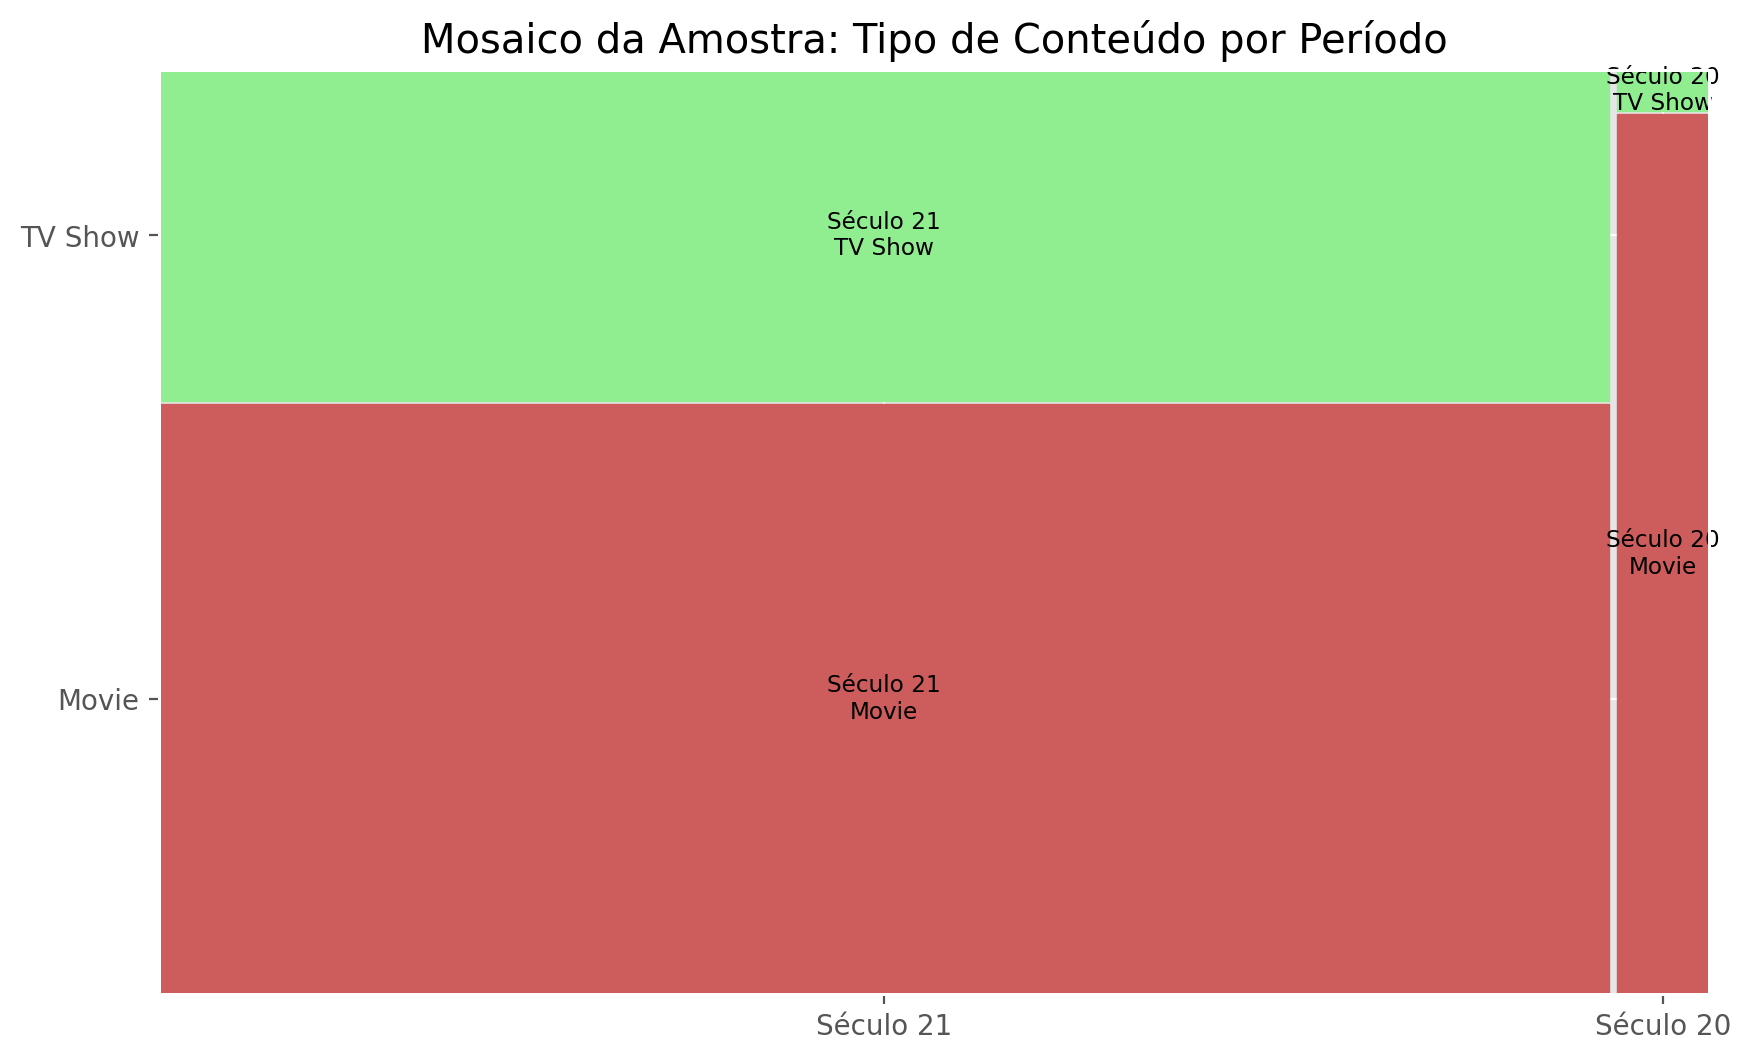

In [353]:
import matplotlib.pyplot as plt
from statsmodels.graphics.mosaicplot import mosaic

# Corrigindo o erro de sintaxe do facecolor e ajustando as propriedades do mosaico
fig, ax = plt.subplots(figsize=(10, 6), facecolor='white')

# Vamos definir propriedades visuais de cores para as categorias
props = lambda key: {'color': 'indianred' if 'Movie' in key else 'lightgreen'}

mosaic(amostra_df, ['periodo', 'type'],
       title='Mosaico da Amostra: Tipo de Conteúdo por Período',
       properties=props, ax=ax)

plt.show()

In [354]:
import statsmodels.api as sm
import numpy as np

# Vamos obter as contagens necessárias para o teste de duas proporções na nossa amostra
# Comparando Século 20 vs Século 21
try:
    # Sucessos (Séries / TV Show) em cada período
    s_seculo20 = tabela_amostra.loc['Século 20', 'TV Show']
    s_seculo21 = tabela_amostra.loc['Século 21', 'TV Show']

    # Total de observações em cada período na amostra
    n_seculo20 = tabela_amostra.loc['Século 20'].sum()
    n_seculo21 = tabela_amostra.loc['Século 21'].sum()

    print("=== DADOS DA AMOSTRA PARA O TESTE ===")
    print(f"Século 20: {s_seculo20} Séries de um total de {n_seculo20} títulos (Proporção: {s_seculo20/n_seculo20:.2%})")
    print(f"Século 21: {s_seculo21} Séries de um total de {n_seculo21} títulos (Proporção: {s_seculo21/n_seculo21:.2%})")

    # Teste Z para duas proporções independentes
    successes = np.array([s_seculo20, s_seculo21])
    nobs = np.array([n_seculo20, n_seculo21])

    z_stat, p_val = sm.stats.proportions_ztest(successes, nobs, alternative='two-sided')

    print("\n=== TESTE Z PARA DUAS PROPORÇÕES (Séries no Século 20 vs Século 21) ===")
    print(f"Estatística Z: {z_stat:.4f}")
    print(f"p-valor: {p_val:.4g}")

    alpha = 0.05
    if p_val < alpha:
        print("\nResultado: Rejeitamos a hipótese nula ($H_0$).")
        print("A proporção de séries em relação a filmes é significativamente diferente entre os séculos na amostra.")
    else:
        print("\nResultado: Não rejeitamos a hipótese nula ($H_0$).")
        print("Não há diferença estatisticamente significativa na proporção de séries entre os séculos na amostra.")
except Exception as e:
    print(f"Erro ao executar o teste: {e}. Verifique se a amostragem foi executada previamente.")

=== DADOS DA AMOSTRA PARA O TESTE ===
Século 20: 1 Séries de um total de 22 títulos (Proporção: 4.55%)
Século 21: 125 Séries de um total de 347 títulos (Proporção: 36.02%)

=== TESTE Z PARA DUAS PROPORÇÕES (Séries no Século 20 vs Século 21) ===
Estatística Z: -3.0193
p-valor: 0.002534

Resultado: Rejeitamos a hipótese nula ($H_0$).
A proporção de séries em relação a filmes é significativamente diferente entre os séculos na amostra.
